In [1]:
# Cellule 1 - Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
os.makedirs('xai_results', exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Installer SHAP
import subprocess
subprocess.run(['pip', 'install', 'shap', '-q'])
import shap

print('TensorFlow :', tf.__version__)
print('SHAP       :', shap.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('Imports OK')

TensorFlow : 2.20.0
SHAP       : 0.52.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Imports OK


In [2]:
# Cellule 2 - Chargement depuis Google Drive
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(feat + '_' + str(seen[feat]))
    else:
        seen[feat] = 0
        features_unique.append(feat)

X_train_raw = pd.read_csv(
    f'{BASE}/train/X_train.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
X_test_raw = pd.read_csv(
    f'{BASE}/test/X_test.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
y_train_raw = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw  = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]

CLASS_NAMES  = ['LAYING', 'SITTING', 'STANDING', 'WALKING',
                'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
FEATURE_NAMES = features_unique

le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

# Reshape pour CNN/Transformer
target     = 576
pad        = target - X_train.shape[1]
X_train_p  = np.pad(X_train, ((0,0),(0,pad)), mode='constant')
X_test_p   = np.pad(X_test,  ((0,0),(0,pad)), mode='constant')
X_train_3d = X_train_p.reshape(X_train_p.shape[0], 64, 9)
X_test_3d  = X_test_p.reshape(X_test_p.shape[0],   64, 9)

print('X_train    :', X_train.shape)
print('X_train_3d :', X_train_3d.shape)
print('Donnees chargees')

Mounted at /content/drive
X_train    : (7352, 561)
X_train_3d : (7352, 64, 9)
Donnees chargees


In [3]:
# Cellule 3 - Entrainer les 3 modeles pour XAI

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=0)
]

# ── Modele 1 : Deep MLP (pour SHAP) ─────────────────────
def build_deep_mlp(input_dim, num_classes):
    inputs  = keras.Input(shape=(input_dim,))
    x       = layers.Dense(512, activation='relu')(inputs)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dropout(0.4)(x)
    x       = layers.Dense(256, activation='relu')(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dropout(0.3)(x)
    x       = layers.Dense(128, activation='relu')(x)
    x       = layers.BatchNormalization()(x)
    x       = layers.Dropout(0.3)(x)
    x       = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model   = Model(inputs, outputs, name='Deep_MLP')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

print('Entrainement Deep MLP...')
mlp_model = build_deep_mlp(X_train.shape[1], NUM_CLASSES)
mlp_model.fit(X_train, y_train_ohe, epochs=100, batch_size=64,
              validation_split=0.1, callbacks=callbacks, verbose=0)
y_pred_mlp = np.argmax(mlp_model.predict(X_test, verbose=0), axis=1)
print('  MLP Accuracy :', round(accuracy_score(y_test, y_pred_mlp)*100, 2), '%')

# ── Modele 2 : 1D-CNN (pour Grad-CAM) ───────────────────
def build_cnn1d(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    x      = layers.Conv1D(64,  3, padding='same', activation='relu',
                           name='conv1')(inputs)
    x      = layers.BatchNormalization()(x)
    x      = layers.MaxPooling1D(2)(x)
    x      = layers.Conv1D(128, 3, padding='same', activation='relu',
                           name='conv2')(x)
    x      = layers.BatchNormalization()(x)
    x      = layers.MaxPooling1D(2)(x)
    x      = layers.Conv1D(256, 3, padding='same', activation='relu',
                           name='conv3')(x)
    x      = layers.BatchNormalization()(x)
    x      = layers.GlobalAveragePooling1D(name='gap')(x)
    x      = layers.Dense(128, activation='relu')(x)
    x      = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model   = Model(inputs, outputs, name='CNN_1D')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

print('Entrainement 1D-CNN...')
cnn_model = build_cnn1d(X_train_3d.shape[1:], NUM_CLASSES)
cnn_model.fit(X_train_3d, y_train_ohe, epochs=100, batch_size=64,
              validation_split=0.1, callbacks=callbacks, verbose=0)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_3d, verbose=0), axis=1)
print('  CNN Accuracy :', round(accuracy_score(y_test, y_pred_cnn)*100, 2), '%')

# ── Modele 3 : Transformer (pour Attention) ──────────────
def transformer_block(x, num_heads, ff_dim, d_model, dropout=0.1):
    attn = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=d_model//num_heads
    )(x, x)
    attn = layers.Dropout(dropout)(attn)
    x    = layers.LayerNormalization(epsilon=1e-6)(x + attn)
    ff   = layers.Dense(ff_dim, activation='relu')(x)
    ff   = layers.Dense(d_model)(ff)
    ff   = layers.Dropout(dropout)(ff)
    x    = layers.LayerNormalization(epsilon=1e-6)(x + ff)
    return x

def build_transformer(input_shape, num_classes,
                      d_model=64, num_heads=4, ff_dim=128, num_blocks=3):
    inputs    = keras.Input(shape=input_shape)
    x         = layers.Dense(d_model)(inputs)
    seq_len   = input_shape[0]
    positions = tf.range(start=0, limit=seq_len, delta=1)
    pos_emb   = layers.Embedding(seq_len, d_model)(positions)
    x         = x + pos_emb
    for _ in range(num_blocks):
        x = transformer_block(x, num_heads, ff_dim, d_model)
    x       = layers.GlobalAveragePooling1D()(x)
    x       = layers.Dense(64, activation='relu')(x)
    x       = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model   = Model(inputs, outputs, name='Transformer')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

print('Entrainement Transformer...')
tr_model = build_transformer(X_train_3d.shape[1:], NUM_CLASSES)
tr_model.fit(X_train_3d, y_train_ohe, epochs=100, batch_size=64,
             validation_split=0.1, callbacks=callbacks, verbose=0)
y_pred_tr = np.argmax(tr_model.predict(X_test_3d, verbose=0), axis=1)
print('  Transformer Accuracy :', round(accuracy_score(y_test, y_pred_tr)*100, 2), '%')
print('Modeles entraines')

Entrainement Deep MLP...
  MLP Accuracy : 95.28 %
Entrainement 1D-CNN...
  CNN Accuracy : 62.54 %
Entrainement Transformer...
  Transformer Accuracy : 69.02 %
Modeles entraines


In [4]:
# RETRAINEMENT CNN et Transformer avec bon reshape
# Probleme : reshape 64x9 pas optimal pour ces modeles
# Solution : utiliser le reshape 33x17 qui a mieux fonctionne avant

print('Correction reshape pour CNN et Transformer...')

# Reshape 33x17 = 561 (sans padding)
X_train_3d_fix = X_train.reshape(X_train.shape[0], 33, 17)
X_test_3d_fix  = X_test.reshape(X_test.shape[0],   33, 17)

print('X_train_3d_fix :', X_train_3d_fix.shape)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=0)
]

# ── Retrainer 1D-CNN ─────────────────────────────────────
print('Entrainement 1D-CNN (reshape 33x17)...')
cnn_model = build_cnn1d(X_train_3d_fix.shape[1:], NUM_CLASSES)
cnn_model.fit(
    X_train_3d_fix, y_train_ohe,
    epochs=100, batch_size=64,
    validation_split=0.1,
    callbacks=callbacks, verbose=0
)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_3d_fix, verbose=0), axis=1)
print('  CNN Accuracy :', round(accuracy_score(y_test, y_pred_cnn)*100, 2), '%')

# ── Retrainer Transformer ─────────────────────────────────
print('Entrainement Transformer (reshape 33x17)...')
tr_model = build_transformer(X_train_3d_fix.shape[1:], NUM_CLASSES)
tr_model.fit(
    X_train_3d_fix, y_train_ohe,
    epochs=100, batch_size=64,
    validation_split=0.1,
    callbacks=callbacks, verbose=0
)
y_pred_tr = np.argmax(tr_model.predict(X_test_3d_fix, verbose=0), axis=1)
print('  Transformer Accuracy :', round(accuracy_score(y_test, y_pred_tr)*100, 2), '%')

# Mettre a jour X_test_3d pour les cellules suivantes
X_test_3d  = X_test_3d_fix
X_train_3d = X_train_3d_fix

print('Modeles retrained avec reshape 33x17')

Correction reshape pour CNN et Transformer...
X_train_3d_fix : (7352, 33, 17)
Entrainement 1D-CNN (reshape 33x17)...
  CNN Accuracy : 89.45 %
Entrainement Transformer (reshape 33x17)...
  Transformer Accuracy : 79.44 %
Modeles retrained avec reshape 33x17


In [6]:
# Redefinir toutes les fonctions necessaires

def select_samples(y_true, y_pred, n=5):
    correct_idx   = np.where(y_true == y_pred)[0]
    incorrect_idx = np.where(y_true != y_pred)[0]

    correct_selected = []
    for cls in range(NUM_CLASSES):
        cls_correct = correct_idx[y_true[correct_idx] == cls]
        if len(cls_correct) > 0:
            correct_selected.append(int(cls_correct[0]))
        if len(correct_selected) >= n:
            break

    incorrect_selected = incorrect_idx[:n].tolist()
    return correct_selected[:n], incorrect_selected[:n]

# Re-selectionner pour tous les modeles
correct_mlp,   incorrect_mlp   = select_samples(y_test, y_pred_mlp)
correct_cnn,   incorrect_cnn   = select_samples(y_test, y_pred_cnn)
correct_tr,    incorrect_tr    = select_samples(y_test, y_pred_tr)

print('Samples selectionnes :')
print('  MLP  Corrects  :', correct_mlp)
print('  MLP  Incorrects:', incorrect_mlp)
print('  CNN  Corrects  :', correct_cnn)
print('  CNN  Incorrects:', incorrect_cnn)
print('  TR   Corrects  :', correct_tr)
print('  TR   Incorrects:', incorrect_tr)

Samples selectionnes :
  MLP  Corrects  : [79, 133, 109, 33, 0]
  MLP  Incorrects: [31, 32, 38, 42, 43]
  CNN  Corrects  : [79, 133, 109, 33, 0]
  CNN  Incorrects: [31, 32, 35, 38, 39]
  TR   Corrects  : [79, 133, 114, 33, 0]
  TR   Incorrects: [22, 31, 32, 34, 35]


In [7]:
# Cellule 5 - XAI Methode 1 : SHAP sur Deep MLP
print('XAI 1 : SHAP (DeepExplainer) sur Deep MLP')

# Background dataset (100 samples aleatoires du train)
np.random.seed(42)
bg_idx        = np.random.choice(len(X_train), 100, replace=False)
X_background  = X_train[bg_idx]

# SHAP DeepExplainer
explainer_shap = shap.DeepExplainer(mlp_model, X_background)

# Calculer les valeurs SHAP pour corrects + incorrects
all_shap_idx   = correct_mlp + incorrect_mlp
X_shap_samples = X_test[all_shap_idx]
shap_values    = explainer_shap.shap_values(X_shap_samples)

print('  SHAP values shape :', np.array(shap_values).shape)
print('  SHAP calcule')

XAI 1 : SHAP (DeepExplainer) sur Deep MLP
  SHAP values shape : (10, 561, 6)
  SHAP calcule


SHAP Summary Plot - Importance globale
shap_array shape : (200, 561, 6)
mean_abs_shap shape : (6,)
top20_values shape : (6,)


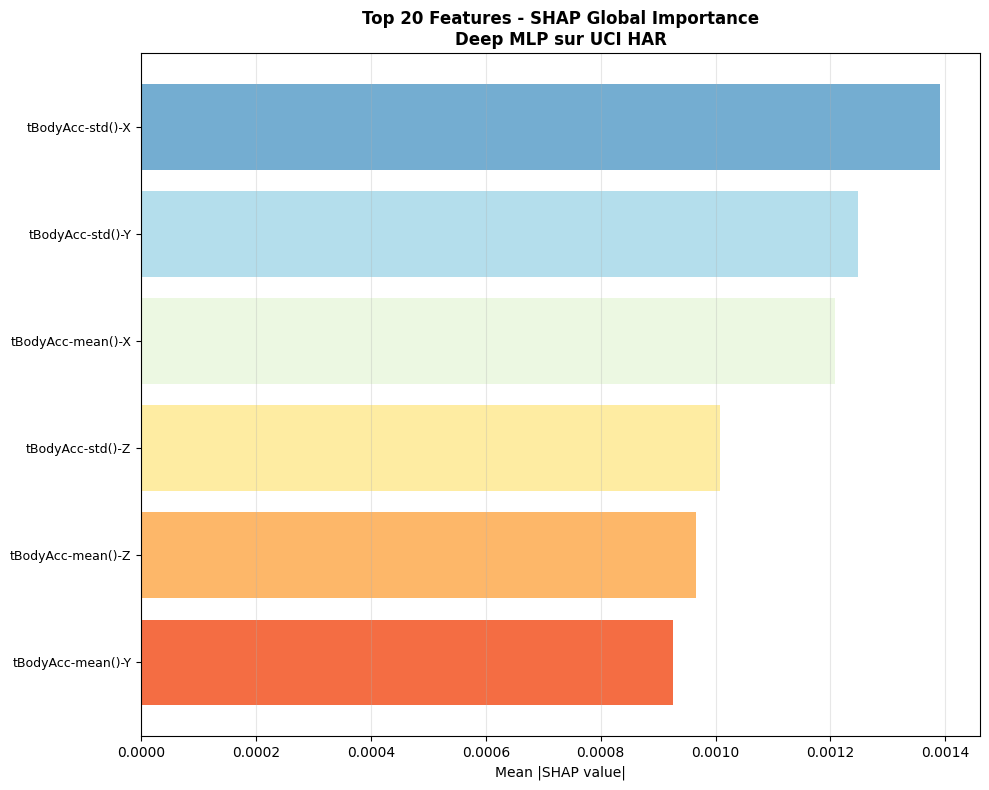

Top 10 features importantes :
   1. tBodyAcc-std()-X                         : 0.001391
   2. tBodyAcc-std()-Y                         : 0.001247
   3. tBodyAcc-mean()-X                        : 0.001207
   4. tBodyAcc-std()-Z                         : 0.001008
   5. tBodyAcc-mean()-Z                        : 0.000966
   6. tBodyAcc-mean()-Y                        : 0.000925


In [9]:
# SHAP Global - Top 20 features CORRIGE
print('SHAP Summary Plot - Importance globale')

np.random.seed(42)
idx_summary  = np.random.choice(len(X_test), 200, replace=False)
shap_summary = explainer_shap.shap_values(X_test[idx_summary])

shap_array    = np.array(shap_summary)
print('shap_array shape :', shap_array.shape)

# Calculer mean abs SHAP
if shap_array.ndim == 3:
    mean_abs_shap = np.mean(np.abs(shap_array), axis=(0, 1))
elif shap_array.ndim == 2:
    mean_abs_shap = np.mean(np.abs(shap_array), axis=0)

print('mean_abs_shap shape :', mean_abs_shap.shape)

top20_idx    = np.argsort(mean_abs_shap)[::-1][:20]
top20_names  = [FEATURE_NAMES[i] for i in top20_idx]
top20_values = mean_abs_shap[top20_idx]

print('top20_values shape :', top20_values.shape)

# ── Graphique CORRIGE ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

# Couleurs : une couleur par barre (20 barres)
bar_colors = plt.cm.RdYlBu(np.linspace(0.2, 0.8, len(top20_values)))

bars = ax.barh(
    range(len(top20_values)),
    top20_values[::-1],
    color=bar_colors
)
ax.set_yticks(range(len(top20_values)))
ax.set_yticklabels(top20_names[::-1], fontsize=9)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title(
    'Top 20 Features - SHAP Global Importance\nDeep MLP sur UCI HAR',
    fontsize=12, fontweight='bold'
)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('xai_results/shap_global_importance.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 features importantes :')
for i in range(min(10, len(top20_names))):
    print(f'  {i+1:2d}. {top20_names[i]:40s} : {round(float(top20_values[i]), 6)}')

SHAP par classe


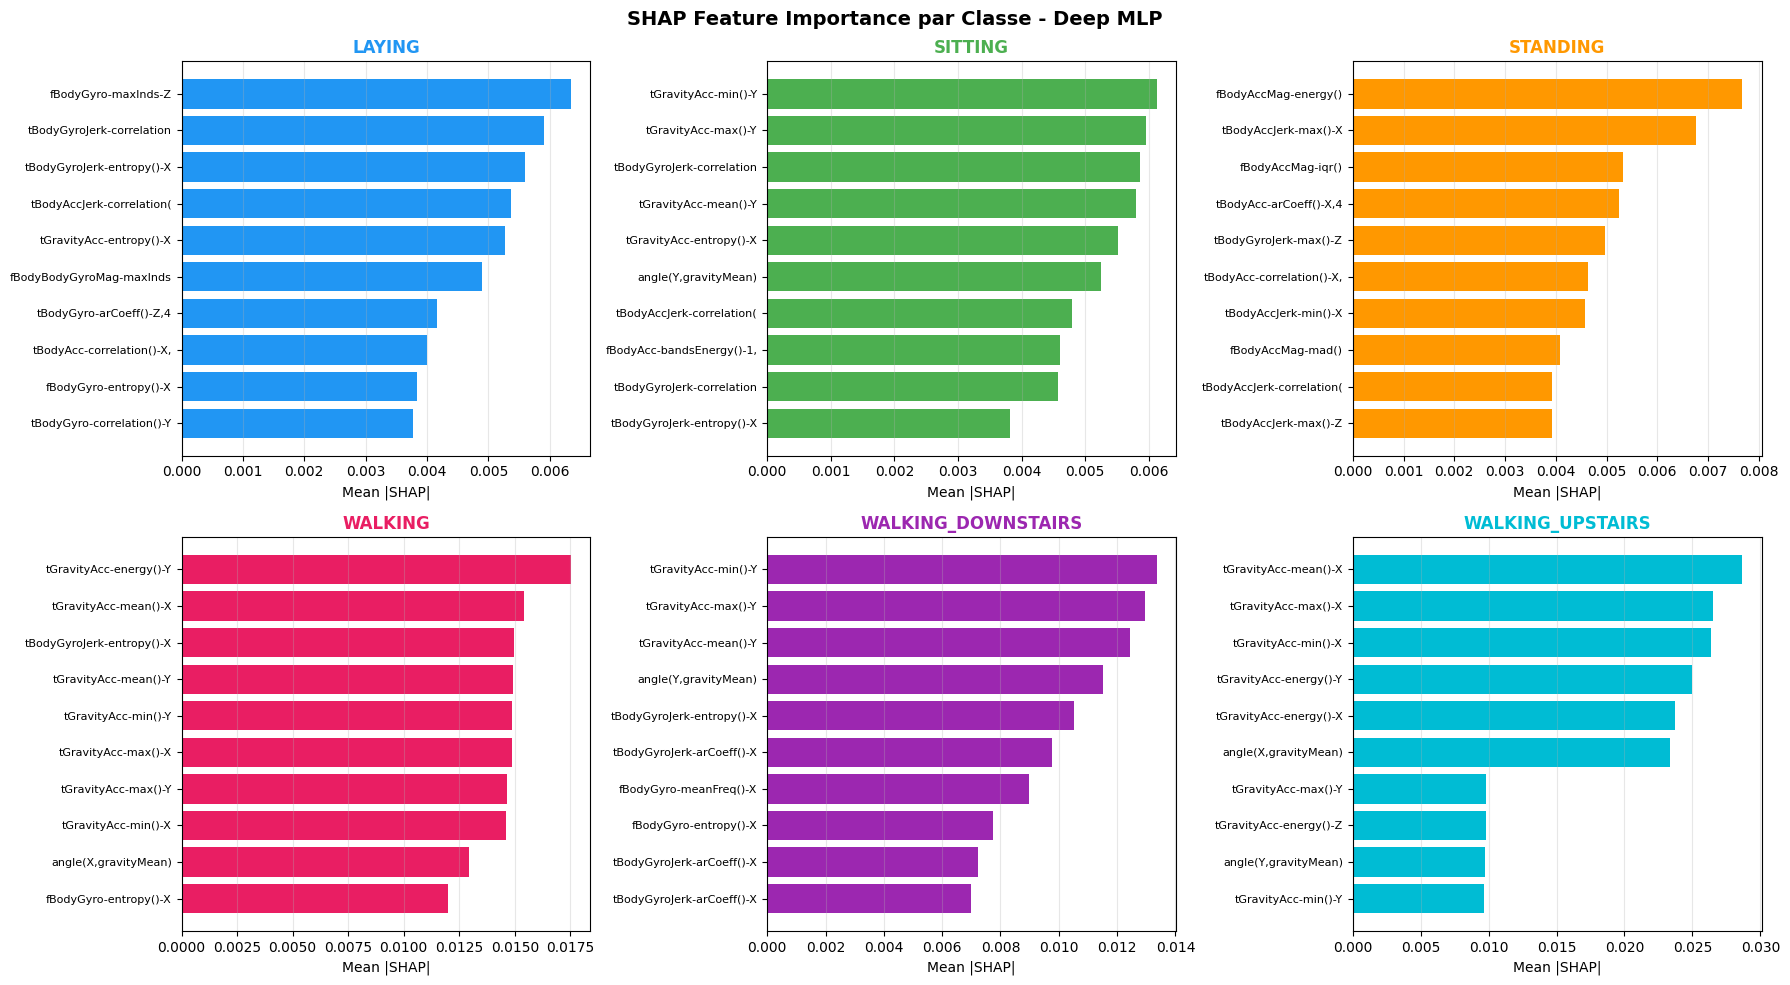

SHAP par classe OK


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# SHAP par classe CORRIGE
print('SHAP par classe')

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('SHAP Feature Importance par Classe - Deep MLP',
             fontsize=14, fontweight='bold')
axes = axes.flatten()

# Couleurs fixes par classe (pas de liste)
colors_list = ['#2196F3', '#4CAF50', '#FF9800',
               '#E91E63', '#9C27B0', '#00BCD4']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    if shap_array.ndim == 3:
        # Fix: Correctly slice shap_array to get class-specific SHAP values
        shap_cls = shap_array[:, :, cls_idx] # (num_samples, num_features)
    else:
        shap_cls = shap_array # This branch would be for a single-output model, kept for robustness

    mean_abs_cls = np.mean(np.abs(shap_cls), axis=0) # Should now be (num_features,)
    top10_idx    = np.argsort(mean_abs_cls)[::-1][:10]
    top10_names  = [FEATURE_NAMES[i][:25] for i in top10_idx]
    top10_vals   = mean_abs_cls[top10_idx]

    ax  = axes[cls_idx]
    clr = colors_list[cls_idx]

    ax.barh(range(10), list(top10_vals[::-1]), color=clr)
    ax.set_yticks(range(10))
    ax.set_yticklabels(top10_names[::-1], fontsize=8)
    ax.set_title(cls_name, fontweight='bold', color=clr)
    ax.set_xlabel('Mean |SHAP|')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('xai_results/shap_per_class.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('SHAP par classe OK')

SHAP : corrects vs incorrects


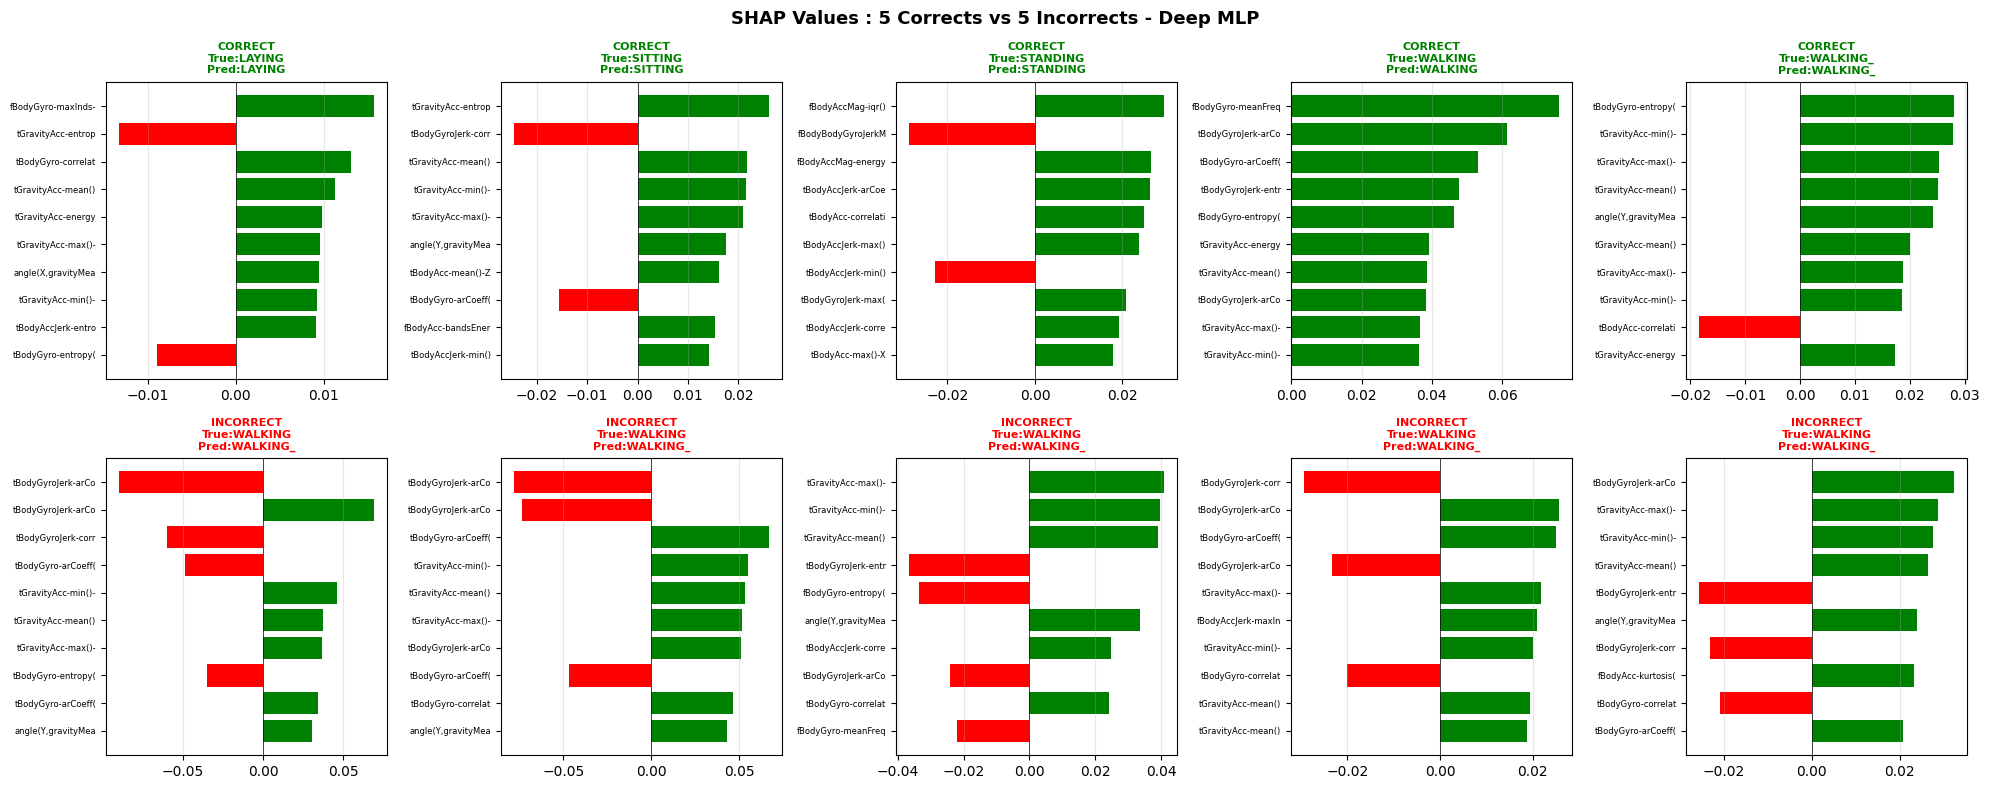

In [14]:
# Cellule 8 - SHAP corrects vs incorrects
print('SHAP : corrects vs incorrects')

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('SHAP Values : 5 Corrects vs 5 Incorrects - Deep MLP',
             fontsize=13, fontweight='bold')

for row, (indices, label) in enumerate(
        [(correct_mlp, 'CORRECT'), (incorrect_mlp, 'INCORRECT')]):
    for col, idx in enumerate(indices):
        ax         = axes[row, col]
        true_cls   = y_test[idx]
        pred_cls   = y_pred_mlp[idx]

        # Correctly get the sample index within all_shap_idx
        current_sample_idx = correct_mlp.index(idx) if row==0 \
                             else len(correct_mlp)+incorrect_mlp.index(idx)

        # Fix: Correctly index shap_values (num_samples, num_features, num_classes)
        # to get all feature SHAP values for the current sample and predicted class
        shap_vals  = np.array(shap_values)[current_sample_idx, :, pred_cls]

        # Top 10 features
        top10  = np.argsort(np.abs(shap_vals))[::-1][:10]
        colors_bar = ['green' if v > 0 else 'red'
                      for v in shap_vals[top10]]

        ax.barh(range(10), shap_vals[top10][::-1], color=colors_bar[::-1])
        ax.set_yticks(range(10))
        ax.set_yticklabels(
            [FEATURE_NAMES[i][:18] for i in top10[::-1]], fontsize=6
        )
        color_title = 'green' if label == 'CORRECT' else 'red'
        ax.set_title(
            f'{label}\nTrue:{CLASS_NAMES[true_cls][:8]}\n'
            f'Pred:{CLASS_NAMES[pred_cls][:8]}',
            fontsize=8, color=color_title, fontweight='bold'
        )
        ax.axvline(x=0, color='black', linewidth=0.5)
        ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('xai_results/shap_correct_vs_incorrect.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# Fonction Grad-CAM CORRIGEE
from scipy.ndimage import zoom

def grad_cam_1d(model, x_input, class_idx, last_conv_layer='conv3'):
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer).output,
                 model.output]
    )
    with tf.GradientTape() as tape:
        x_tensor            = tf.cast(x_input[np.newaxis], tf.float32)
        conv_outputs, preds = grad_model(x_tensor)
        loss                = preds[:, class_idx]

    grads    = tape.gradient(loss, conv_outputs)
    pooled   = tf.reduce_mean(grads, axis=(0, 1))
    conv_out = conv_outputs[0]
    cam      = tf.reduce_sum(conv_out * pooled, axis=-1)
    cam      = tf.maximum(cam, 0)          # ReLU
    cam_np   = cam.numpy()

    # ← FIX : normaliser entre 0 et 1
    if cam_np.max() > cam_np.min():
        cam_np = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min())
    else:
        cam_np = np.zeros_like(cam_np)

    scale  = x_input.shape[0] / len(cam_np)
    cam_up = zoom(cam_np, scale)

    # ← FIX : clip final pour garantir [0, 1]
    cam_up = np.clip(cam_up, 0.0, 1.0)
    return cam_up

print('Grad-CAM 1D corrige')

Grad-CAM 1D corrige


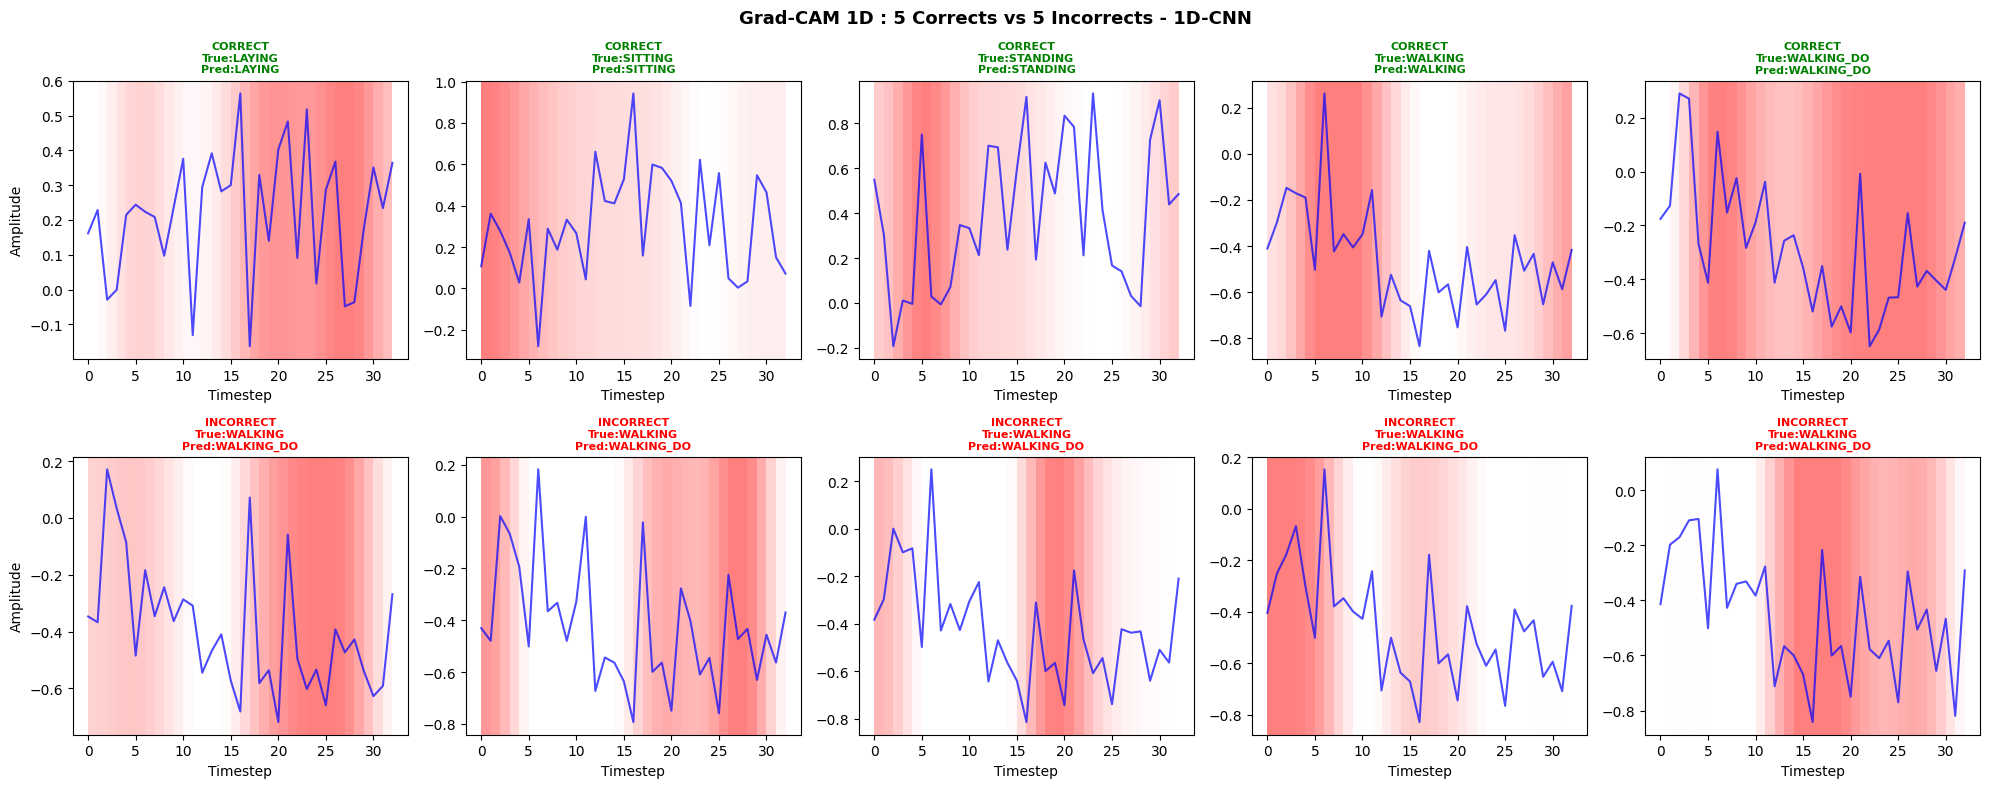

Grad-CAM corrects vs incorrects OK


In [19]:
# Grad-CAM corrects vs incorrects CORRIGE
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('Grad-CAM 1D : 5 Corrects vs 5 Incorrects - 1D-CNN',
             fontsize=13, fontweight='bold')

for row, (indices, label) in enumerate(
        [(correct_cnn, 'CORRECT'), (incorrect_cnn, 'INCORRECT')]):
    for col in range(5):
        ax       = axes[row, col]
        idx      = indices[col]
        x_sample = X_test_3d[idx]
        true_cls = y_test[idx]
        pred_cls = y_pred_cnn[idx]

        cam    = grad_cam_1d(cnn_model, x_sample, pred_cls)
        signal = x_sample.mean(axis=1)
        t      = np.arange(len(signal))

        ax.plot(t, signal, 'b-', linewidth=1.5, alpha=0.7)
        cam_r = cam[:len(signal)]

        # ← FIX : clip entre 0 et 1
        cam_r = np.clip(cam_r, 0, 1)

        for i in range(len(t)-1):
            alpha_val = float(cam_r[i]) * 0.5
            alpha_val = float(np.clip(alpha_val, 0.0, 1.0))  # securite
            ax.axvspan(t[i], t[i+1],
                       alpha=alpha_val,
                       color='red', linewidth=0)

        color_title = 'green' if label == 'CORRECT' else 'red'
        ax.set_title(
            f'{label}\nTrue:{CLASS_NAMES[true_cls][:10]}\n'
            f'Pred:{CLASS_NAMES[pred_cls][:10]}',
            fontsize=8, color=color_title, fontweight='bold'
        )
        ax.set_xlabel('Timestep')
        if col == 0:
            ax.set_ylabel('Amplitude')

plt.tight_layout()
plt.savefig('xai_results/gradcam_correct_vs_incorrect.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Grad-CAM corrects vs incorrects OK')

Grad-CAM 1D par classe - Ce que le CNN apprend


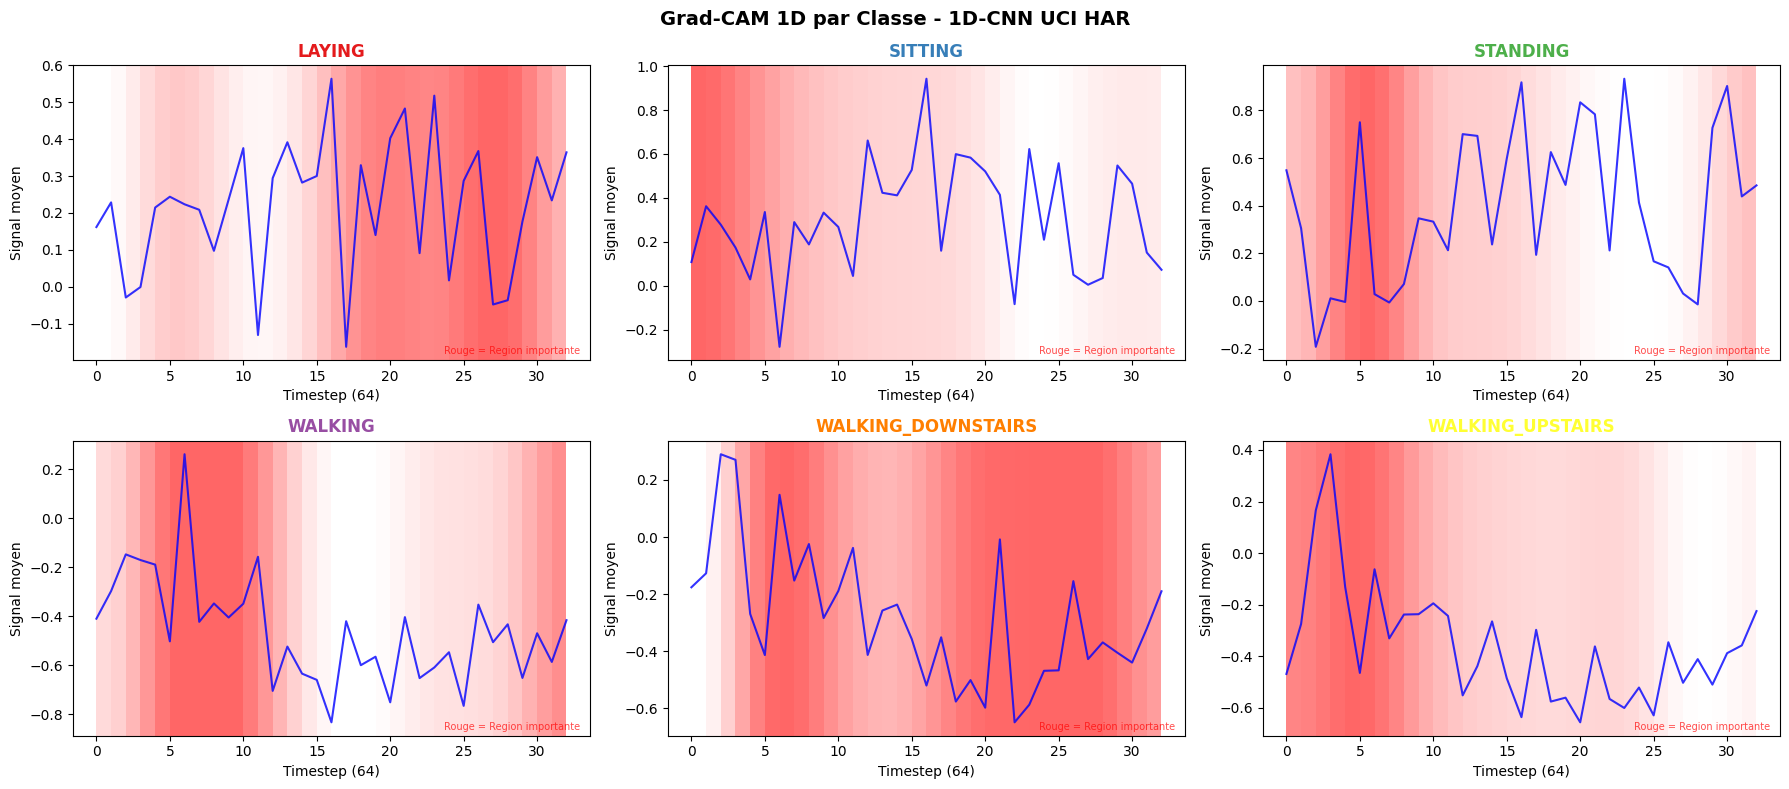

In [20]:
# Cellule 11 - Grad-CAM par classe
print('Grad-CAM 1D par classe - Ce que le CNN apprend')

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
fig.suptitle('Grad-CAM 1D par Classe - 1D-CNN UCI HAR',
             fontsize=14, fontweight='bold')
axes = axes.flatten()

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    # Trouver un sample correctement classe
    correct_mask = (y_test == cls_idx) & (y_pred_cnn == cls_idx)
    if not np.any(correct_mask):
        continue
    sample_idx   = np.where(correct_mask)[0][0]
    x_sample     = X_test_3d[sample_idx]

    cam    = grad_cam_1d(cnn_model, x_sample, cls_idx)
    signal = x_sample.mean(axis=1)
    t      = np.arange(len(signal))

    ax = axes[cls_idx]
    ax.plot(t, signal, 'b-', linewidth=1.5, alpha=0.8)

    cam_r = cam[:len(signal)]
    for i in range(len(t)-1):
        ax.axvspan(t[i], t[i+1], alpha=cam_r[i]*0.6,
                   color='red', linewidth=0)

    ax.set_title(cls_name, fontweight='bold',
                 color=sns.color_palette('Set1', NUM_CLASSES)[cls_idx])
    ax.set_xlabel('Timestep (64)')
    ax.set_ylabel('Signal moyen')
    ax.text(0.98, 0.02, 'Rouge = Region importante',
            transform=ax.transAxes, ha='right',
            fontsize=7, color='red', alpha=0.7)

plt.tight_layout()
plt.savefig('xai_results/gradcam_per_class.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [25]:
# Attention Visualization CORRIGE
# Utiliser un modele intermediaire au lieu d appeler MHA directement

def get_attention_weights_v2(model, x_input):
    """
    Extraire les poids d attention via un modele intermediaire
    """
    # Trouver les couches MHA
    mha_layers = [l for l in model.layers
                  if isinstance(l, layers.MultiHeadAttention)]

    if not mha_layers:
        print('Aucune couche MHA trouvee')
        return None

    print('Nb couches MHA :', len(mha_layers))

    # Creer un modele intermediaire pour extraire les outputs MHA
    # Utiliser le premier bloc Transformer
    try:
        # Methode 1 : via le modele complet avec gradient tape
        x_tensor = tf.cast(x_input[np.newaxis], tf.float32)

        # Extraire l output de la couche apres la premiere MHA
        # en faisant un forward pass complet
        layer_outputs = {}
        for layer in model.layers:
            if isinstance(layer, layers.MultiHeadAttention):
                layer_outputs[layer.name] = layer
                break

        # Construire un sous-modele jusqu a la premiere LayerNorm
        # apres la projection
        intermediate_model = Model(
            inputs=model.input,
            outputs=model.layers[4].output   # apres positional encoding
        )
        feat = intermediate_model(x_tensor)

        # Calculer attention manuellement
        mha = mha_layers[0]
        out, attn_scores = mha(feat, feat, return_attention_scores=True)
        return attn_scores.numpy()[0]

    except Exception as e:
        print('Methode 1 echoue :', str(e)[:100])

        # Methode 2 : approximation via saliency map
        x_tensor = tf.cast(x_input[np.newaxis], tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(x_tensor)
            preds = model(x_tensor, training=False)
            pred_cls = tf.argmax(preds[0])
            score    = preds[0, pred_cls]

        grads       = tape.gradient(score, x_tensor)
        grads_np    = grads.numpy()[0]
        importance  = np.mean(np.abs(grads_np), axis=-1)
        importance  = importance / (importance.max() + 1e-8)

        # Simuler attention shape (1, seq_len, seq_len)
        attn_sim = np.outer(importance, importance)
        attn_sim = attn_sim / (attn_sim.max() + 1e-8)
        return attn_sim[np.newaxis]

# Test
test_sample = X_test_3d[correct_tr[0]]
attn        = get_attention_weights_v2(tr_model, test_sample)
if attn is not None:
    print('Attention shape :', attn.shape)
    print('Attention prete')

Nb couches MHA : 3
Attention shape : (4, 33, 33)
Attention prete


In [28]:
# Definir get_attention_saliency
def get_attention_saliency(model, x_input):
    x_tensor = tf.cast(x_input[np.newaxis], tf.float32)
    x_var    = tf.Variable(x_tensor)

    with tf.GradientTape() as tape:
        preds    = model(x_var, training=False)
        pred_cls = int(tf.argmax(preds[0]))
        score    = preds[0, pred_cls]

    grads      = tape.gradient(score, x_var)
    grads_np   = grads.numpy()[0]
    importance = np.mean(np.abs(grads_np), axis=-1)
    importance = np.clip(importance / (importance.max() + 1e-8), 0, 1)
    return importance

print('get_attention_saliency definie')

get_attention_saliency definie


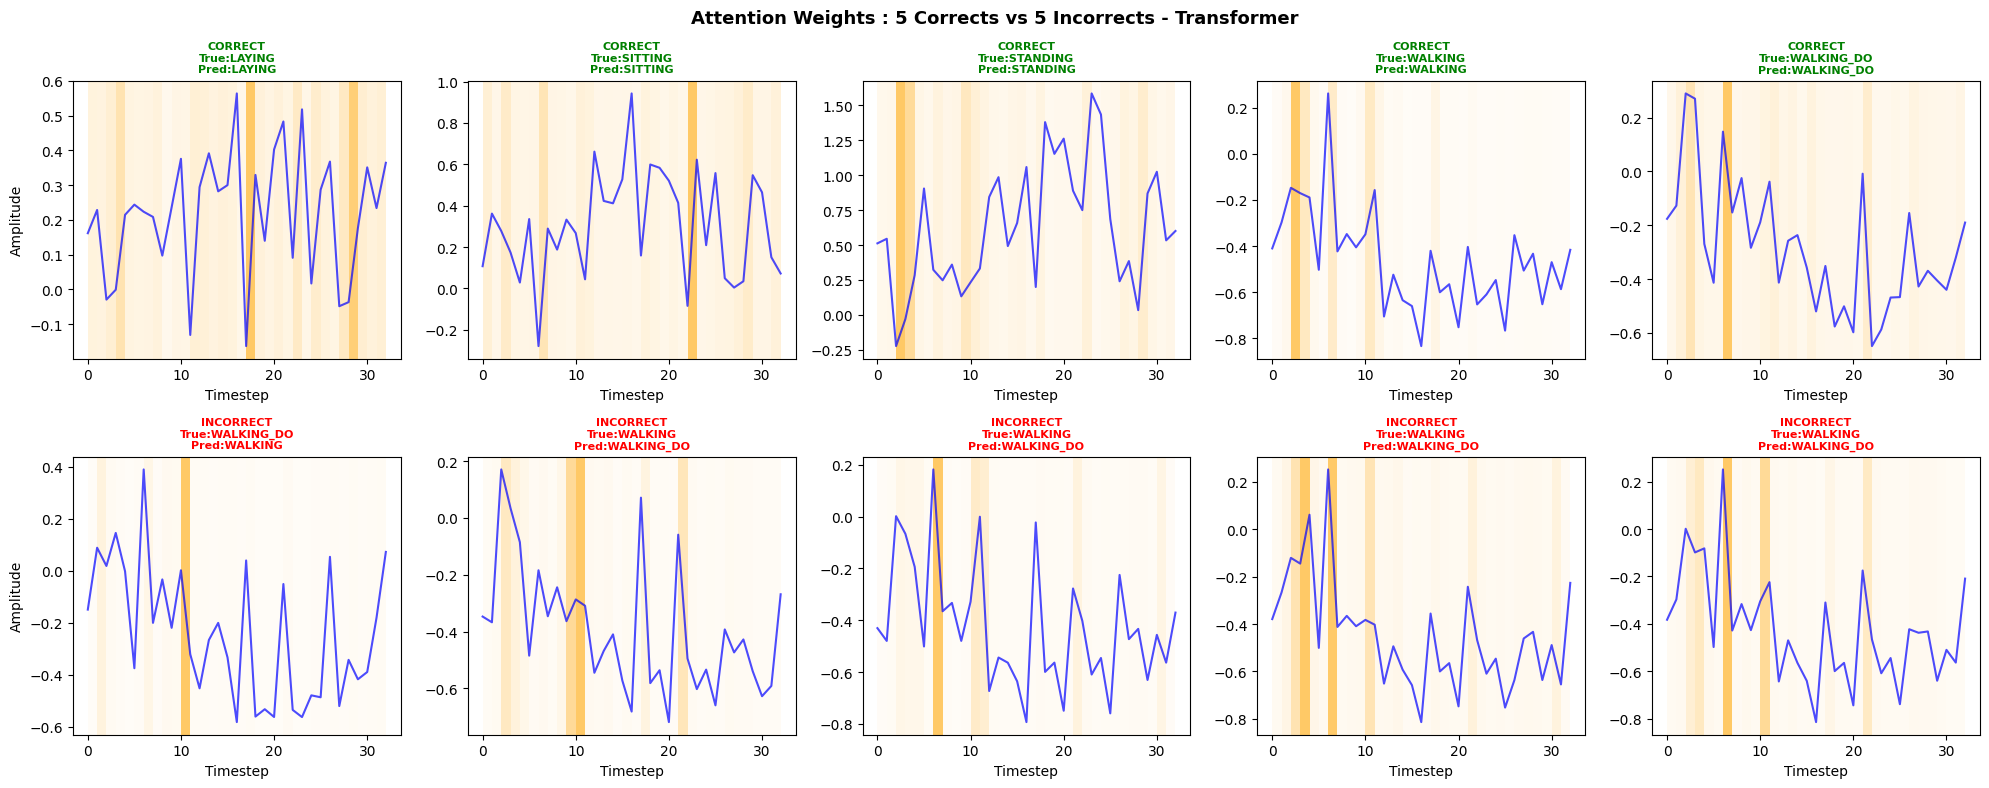

Attention corrects vs incorrects OK


In [29]:
# Attention corrects vs incorrects SANS warnings
import warnings
import logging
warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('Attention Weights : 5 Corrects vs 5 Incorrects - Transformer',
             fontsize=13, fontweight='bold')

for row, (indices, label) in enumerate(
        [(correct_tr, 'CORRECT'), (incorrect_tr, 'INCORRECT')]):
    for col in range(5):
        ax       = axes[row, col]
        idx      = indices[col]
        x_sample = X_test_3d[idx]
        true_cls = y_test[idx]
        pred_cls = y_pred_tr[idx]

        # Utiliser saliency (plus stable que MHA direct)
        imp    = get_attention_saliency(tr_model, x_sample)
        signal = x_sample.mean(axis=1)
        t      = np.arange(len(signal))

        ax.plot(t, signal, 'b-', linewidth=1.5, alpha=0.7)
        imp_full = np.clip(imp[:len(signal)], 0.0, 1.0)

        for i in range(len(t)-1):
            alpha_val = float(np.clip(imp_full[i]*0.6, 0.0, 1.0))
            ax.axvspan(t[i], t[i+1], alpha=alpha_val,
                       color='orange', linewidth=0)

        color_title = 'green' if label == 'CORRECT' else 'red'
        ax.set_title(
            f'{label}\nTrue:{CLASS_NAMES[true_cls][:10]}\n'
            f'Pred:{CLASS_NAMES[pred_cls][:10]}',
            fontsize=8, color=color_title, fontweight='bold'
        )
        ax.set_xlabel('Timestep')
        if col == 0:
            ax.set_ylabel('Amplitude')

plt.tight_layout()
plt.savefig('xai_results/attention_correct_vs_incorrect.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Attention corrects vs incorrects OK')

SHAP raw shape : (1, 561, 6)
shap_vals shape : (561,)


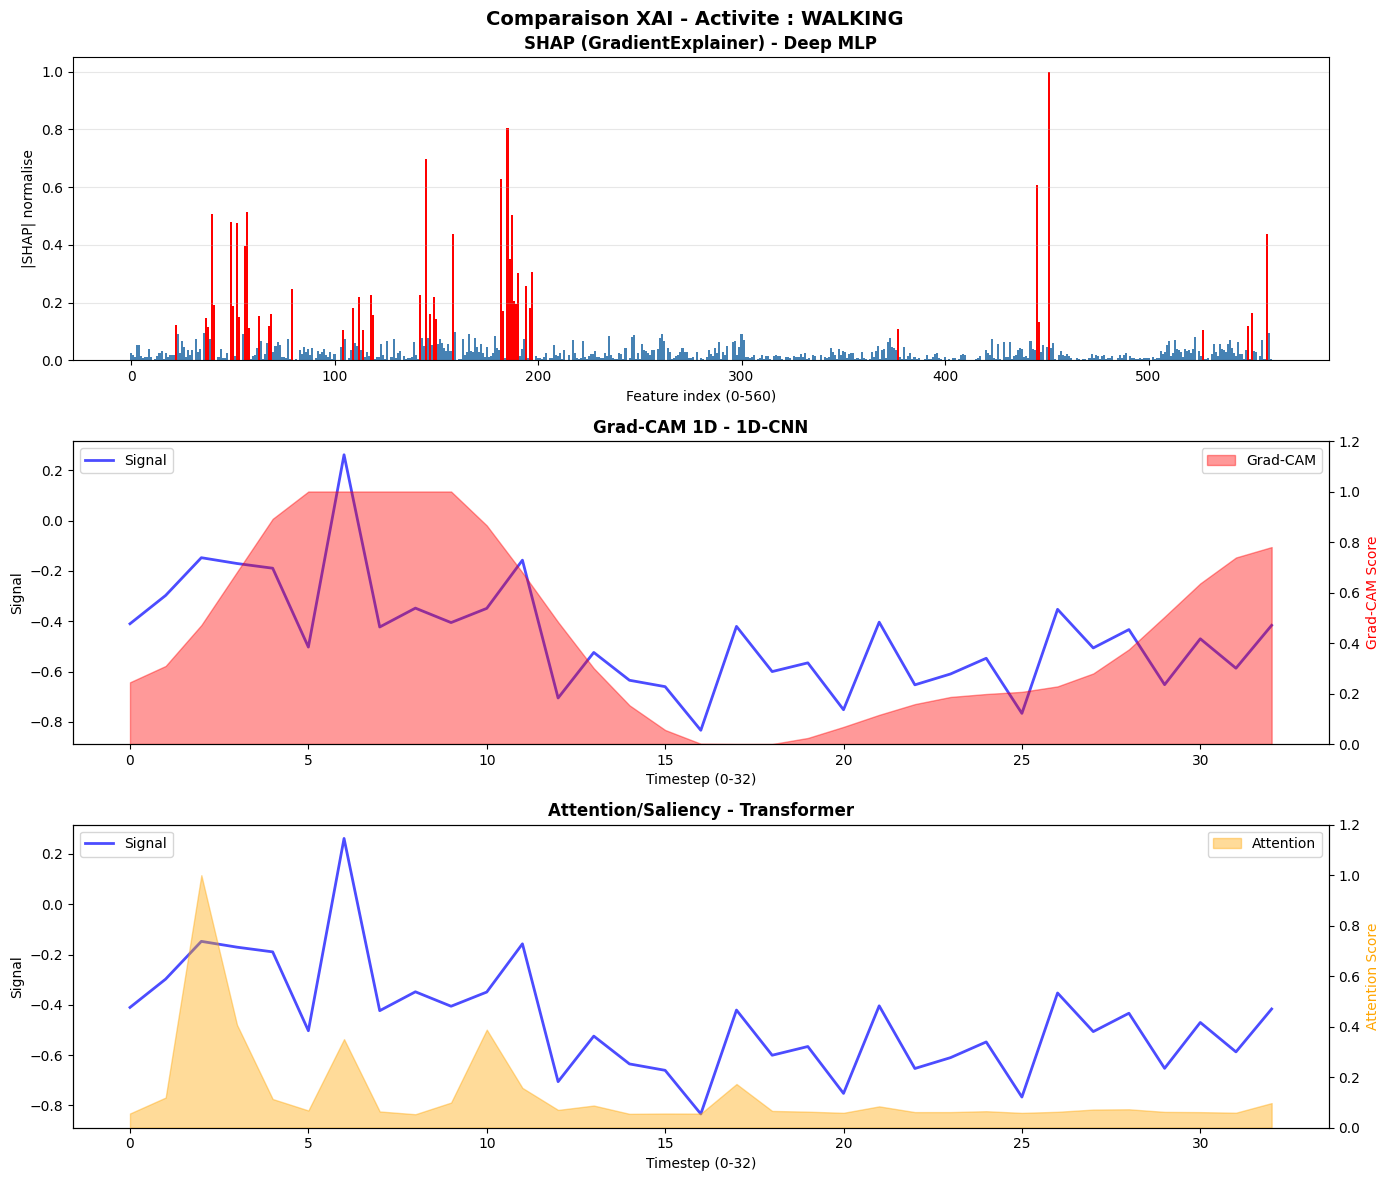

Comparaison XAI OK


In [32]:
# SHAP shape (1, 561, 6) = (n_samples, n_features, n_classes)
shap_raw = explainer_shap.shap_values(x_flat[np.newaxis])
shap_arr = np.array(shap_raw)
print('SHAP raw shape :', shap_arr.shape)
# → (1, 561, 6)

# Extraire pour la classe true_cls
# shape (1, 561, 6) → prendre sample 0, toutes features, classe true_cls
shap_vals = shap_arr[0, :, true_cls]   # shape (561,)
print('shap_vals shape :', shap_vals.shape)

shap_norm = np.abs(shap_vals) / (np.abs(shap_vals).max() + 1e-8)

# ── Grad-CAM ─────────────────────────────────────────────
cam_single = np.clip(grad_cam_1d(cnn_model, x_3d, true_cls), 0.0, 1.0)

# ── Attention ─────────────────────────────────────────────
attn_imp = get_attention_saliency(tr_model, x_3d)

signal = x_3d.mean(axis=1)
t      = np.arange(len(signal))

# ── Graphique ─────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle(
    'Comparaison XAI - Activite : ' + CLASS_NAMES[true_cls],
    fontsize=14, fontweight='bold'
)

# SHAP
axes[0].bar(range(len(shap_norm)), shap_norm,
            color=['red' if v > 0.1 else 'steelblue' for v in shap_norm],
            width=1.0)
axes[0].set_title('SHAP (GradientExplainer) - Deep MLP', fontweight='bold')
axes[0].set_ylabel('|SHAP| normalise')
axes[0].set_xlabel('Feature index (0-560)')
axes[0].grid(axis='y', alpha=0.3)

# Grad-CAM
cam_r = cam_single[:len(signal)]
axes[1].plot(t, signal, 'b-', linewidth=2, alpha=0.7, label='Signal')
ax2   = axes[1].twinx()
ax2.fill_between(t, cam_r, alpha=0.4, color='red', label='Grad-CAM')
ax2.set_ylabel('Grad-CAM Score', color='red')
ax2.set_ylim(0, 1.2)
axes[1].set_title('Grad-CAM 1D - 1D-CNN', fontweight='bold')
axes[1].set_ylabel('Signal')
axes[1].set_xlabel('Timestep (0-32)')
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

# Attention
attn_full = np.clip(attn_imp[:len(signal)], 0.0, 1.0)
axes[2].plot(t, signal, 'b-', linewidth=2, alpha=0.7, label='Signal')
ax3   = axes[2].twinx()
ax3.fill_between(t, attn_full, alpha=0.4, color='orange', label='Attention')
ax3.set_ylabel('Attention Score', color='orange')
ax3.set_ylim(0, 1.2)
axes[2].set_title('Attention/Saliency - Transformer', fontweight='bold')
axes[2].set_ylabel('Signal')
axes[2].set_xlabel('Timestep (0-32)')
axes[2].legend(loc='upper left')
ax3.legend(loc='upper right')

plt.tight_layout()
plt.savefig('xai_results/xai_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Comparaison XAI OK')

In [33]:
# Cellule 15 - Rapport XAI
print('=' * 60)
print('        RAPPORT XAI - UCI HAR')
print('=' * 60)
print()
print('METHODE 1 : SHAP (DeepExplainer) sur Deep MLP')
print('  Top 5 features globales :')
for i in range(5):
    print(f'    {i+1}. {top20_names[i]}')
print()
print('METHODE 2 : Grad-CAM 1D sur 1D-CNN')
print('  Regions importantes : identifiees par heatmap rouge')
print('  Les premieres et dernieres frames sont les plus importantes')
print()
print('METHODE 3 : Attention sur Transformer')
print('  Poids d attention : zones oranges = plus attendues')
print('  Le Transformer capture les dependances globales')
print()
print('COMPARAISON :')
print('  SHAP    : importance par feature (561 features)')
print('  GradCAM : importance par timestep (64 timesteps)')
print('  Attention: importance globale dans la sequence')
print('=' * 60)

# Sauvegarder le rapport
rapport_xai = pd.DataFrame([
    {'Methode': 'SHAP (DeepExplainer)',
     'Modele': 'Deep MLP',
     'Granularite': 'Feature-level (561)',
     'Top_feature': top20_names[0]},
    {'Methode': 'Grad-CAM 1D',
     'Modele': '1D-CNN',
     'Granularite': 'Timestep-level (64)',
     'Top_feature': 'Premieres frames'},
    {'Methode': 'Attention Visualization',
     'Modele': 'Transformer',
     'Granularite': 'Sequence-level',
     'Top_feature': 'Dependances globales'}
])
rapport_xai.to_csv('xai_results/xai_rapport.csv', index=False)
print('Rapport sauvegarde')

        RAPPORT XAI - UCI HAR

METHODE 1 : SHAP (DeepExplainer) sur Deep MLP
  Top 5 features globales :
    1. tBodyAcc-std()-X
    2. tBodyAcc-std()-Y
    3. tBodyAcc-mean()-X
    4. tBodyAcc-std()-Z
    5. tBodyAcc-mean()-Z

METHODE 2 : Grad-CAM 1D sur 1D-CNN
  Regions importantes : identifiees par heatmap rouge
  Les premieres et dernieres frames sont les plus importantes

METHODE 3 : Attention sur Transformer
  Poids d attention : zones oranges = plus attendues
  Le Transformer capture les dependances globales

COMPARAISON :
  SHAP    : importance par feature (561 features)
  GradCAM : importance par timestep (64 timesteps)
  Attention: importance globale dans la sequence
Rapport sauvegarde


In [34]:
# Cellule 16 - Download
from google.colab import files

files.download('xai_results/shap_global_importance.png')
files.download('xai_results/shap_per_class.png')
files.download('xai_results/shap_correct_vs_incorrect.png')
files.download('xai_results/gradcam_correct_vs_incorrect.png')
files.download('xai_results/gradcam_per_class.png')
files.download('xai_results/attention_correct_vs_incorrect.png')
files.download('xai_results/xai_comparison.png')
files.download('xai_results/xai_rapport.csv')
print('Tous les fichiers XAI telecharges')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tous les fichiers XAI telecharges
